# Raw and sign representation comparisons

This exploratory figure reads the completed, fixed-configuration 3-fold cross-validation experiment from `results/representation_ablation/`. Each pair uses the same model settings and data split. In the kNN pair, both representations use training-fitted standardization and Euclidean distance; the earlier sign/Hamming kNN is a different experiment. Error bars show the sample standard deviation across the three scores. Results were used for development and model selection.

The generated PDF is an exploratory figure. Its font embedding and final report formatting have not been verified against the submission requirements.

In [1]:
import csv
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd().resolve()
if root.name == "B_Traditional_ML":
    root = root.parent
results = root / "B_Traditional_ML" / "results" / "representation_ablation"
progress = json.loads((results / "progress.json").read_text(encoding="utf-8"))
assert progress["state"] == "complete" and progress["completed"] == 90 and progress["expected"] == 90

with (results / "summary.csv").open(encoding="utf-8", newline="") as f:
    summary = list(csv.DictReader(f))
with (results / "fold_metrics.csv").open(encoding="utf-8", newline="") as f:
    folds = list(csv.DictReader(f))

datasets = ("20", "30", "40")
methods = ("svm", "xgb", "extra", "knn", "catboost")
representations = ("raw", "sign")
values = defaultdict(list)
for row in folds:
    values[(row["dataset"], row["method"], row["representation"])].append(float(row["accuracy"]))
assert len(folds) == 90
assert len(summary) == 15
for dataset in datasets:
    for method in methods:
        for rep in representations:
            assert len(values[(dataset, method, rep)]) == 3
summary_map = {(r["dataset"], r["method"]): r for r in summary}
for dataset in datasets:
    for method in methods:
        row = summary_map[(dataset, method)]
        assert row["pair_complete"] == "True"
        for rep in representations:
            assert np.isclose(float(row[f"{rep}_mean_accuracy"]), np.mean(values[(dataset, method, rep)]))
print(f"Complete paired models: {len(summary)}; held-out predictions evaluated: {len(folds)} runs.")

Complete paired models: 15; held-out predictions evaluated: 90 runs.


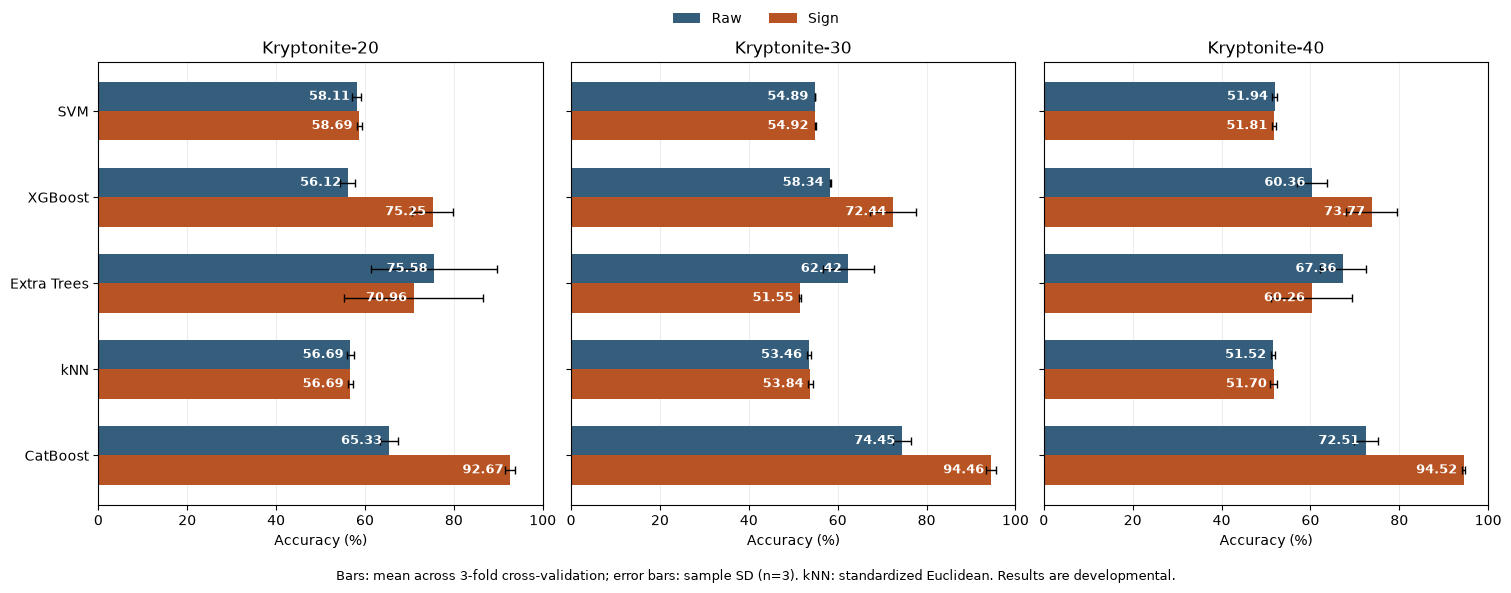

Saved: C:\Users\ROG\OneDrive\桌面\学习助手\Math for ML CW\B_SVM\results\representation_ablation\figures\raw_sign_accuracy.png
Saved: C:\Users\ROG\OneDrive\桌面\学习助手\Math for ML CW\B_SVM\results\representation_ablation\figures\raw_sign_accuracy.pdf


In [2]:
labels = {"svm": "SVM", "xgb": "XGBoost", "extra": "Extra Trees",
          "knn": "kNN", "catboost": "CatBoost"}
colors = {"raw": "#345e7c", "sign": "#b85323"}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True, constrained_layout=True)
y = np.arange(len(methods))
height = 0.34
for ax, dataset in zip(axes, datasets):
    for rep, offset in (("raw", -height / 2), ("sign", height / 2)):
        group = [values[(dataset, method, rep)] for method in methods]
        means = 100 * np.array([np.mean(v) for v in group])
        stds = 100 * np.array([np.std(v, ddof=1) for v in group])
        ax.barh(y + offset, means, height, xerr=stds, color=colors[rep],
                error_kw={"ecolor": "black", "capsize": 3, "elinewidth": 1}, label=rep.capitalize())
        for pos, mean in zip(y + offset, means):
            ax.text(max(1, mean - 1.5), pos, f"{mean:.2f}", va="center", ha="right",
                    color="white", fontsize=9, fontweight="bold")
    ax.set_title(f"Kryptonite-{dataset}", fontsize=12)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_xlabel("Accuracy (%)")
    ax.grid(axis="x", alpha=.22)
    ax.set_axisbelow(True)
axes[0].set_yticks(y, [labels[m] for m in methods])
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center",
           ncols=2, frameon=False)
fig.text(.5, -.05, "Bars: mean across 3-fold cross-validation; error bars: sample SD (n=3). "
         "kNN: standardized Euclidean. Results are developmental.", ha="center", fontsize=9)
figure_dir = results / "figures"
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / "raw_sign_accuracy.png", dpi=180, bbox_inches="tight")
fig.savefig(figure_dir / "raw_sign_accuracy.pdf", bbox_inches="tight")
plt.show()
print("Saved:", figure_dir / "raw_sign_accuracy.png")
print("Saved:", figure_dir / "raw_sign_accuracy.pdf")